[![Open In Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=white)](https://colab.research.google.com/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Binder](https://img.shields.io/badge/Launch-Binder-579ACA?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/ivanvladimir/maquinas_notebooks/HEAD?labpath=basic%2FEjemplo_AFD.ipynb)
[![Open in Kaggle](https://img.shields.io/badge/Open_in-Kaggle-20BEFF?logo=kaggle&logoColor=white)](https://kaggle.com/kernels/welcome?src=https://github.com/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in SageMaker Studio Lab](https://img.shields.io/badge/Open_in-SageMaker_Studio_Lab-FF9900)](https://studiolab.sagemaker.aws/import/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in Deepnote](https://img.shields.io/badge/Open_in-Deepnote-3793EF)](https://deepnote.com/launch?url=https://github.com/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![nbviewer](https://img.shields.io/badge/View_in-nbviewer-F37626?logo=jupyter&logoColor=white)](https://nbviewer.org/github/ivanvladimir/maquinas_notebooks/blob/main/basic/Ejemplo_AFD.ipynb)
[![Open in Codespaces](https://img.shields.io/badge/Open_in-Codespaces-181717?logo=github&logoColor=white)](https://codespaces.new/ivanvladimir/maquinas_notebooks)

Shows different machine of grammars

Navigate sections.

In [99]:
# Load, or install and load the library

try:
    import maquinas
except ImportError:
    %pip install -q git+https://github.com/ivanvladimir/maquinas
    import maquinas

# Autómata finito determinístico

Ejemplifica la creación de un autómata finito determinístico

In [5]:
from maquinas.regular.dfa import DeterministicFiniteAutomaton as DFA
from maquinas.io import load_fa

In [6]:
bes_pares=load_fa("""
        |  a  |  b  |
 ->q_0] | q_0 | q_1 |
   q_1  | q_1 | q_0 |
""")

In [7]:
bes_pares.print_summary()

States  : q_0, q_1
Sigma   : a, b
Initial : q_0
Aceptors: {q_0}
Transitions:
 q_0,a → q_0
 q_0,b → q_1
 q_1,a → q_1
 q_1,b → q_0

In [8]:
bes_pares

In [9]:
bes_pares.table()

,a,b
⟶q_0,q_0,q_1
q_1,q_1,q_0


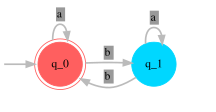

In [11]:
bes_pares.graph()

In [12]:
bes_pares.save_animated_svg("bbaabbbaaaaaaaabaaaaa", show=True)

In [13]:
bes_pares.accepts("bbaabbbaaaaaaaabaaaaa")

True

In [14]:
bes_pares.print_transitions("bbaabbbaaaaaaaabaaaaa")

q_0,
 b → q_1,
 b → q_0,
 a → q_0,
 a → q_0,
 b → q_1,
 b → q_0,
 b → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 a → q_1,
 b → q_0,
 a → q_0,
 a → q_0,
 a → q_0,
 a → q_0,
 a → q_0,
 

In [15]:
res=bes_pares.delta_extended(None,"bbaabbbaaaaaaaabaaaaa")
res

'q_0'

In [16]:
print(f"Con {res} Se acepta?", "Sí" if bes_pares.acceptor(res) else "No" )

Con q_0 Se acepta? Sí


In [17]:
res=bes_pares.delta_extended(None,"bbaabbbaaaaaaaabaaaaab")
print(f"Con {res} Se acepta?", "Sí" if bes_pares.acceptor(res) else "No" )

Con q_1 Se acepta? No


In [18]:
print(f"Con {res} Se acepta?", "Sí" if bes_pares.acceptor(res) else "No" )

Con q_1 Se acepta? No


# Autómata finito no determinístico

Ejemplifica la creación de un autómata finito no determinístico

In [19]:
from maquinas.regular.ndfa import NonDeterministicFiniteAutomaton as NDFA

In [72]:
# Cargando afnd
contains_ab=load_fa("""
        |  a       |  b  |
 ->q_0  | q_0, q_1 | q_0 |
   q_1  | q_0      | q_2 |
   q_2] | q_2      | q_2 |
""")

In [73]:
contains_ab.print_summary()

States  : q_0, q_1, q_2
Sigma   : a, b
Initial : q_0
Aceptors: {q_2}
Transitions:
 q_0,a → {q_0, q_1}
 q_0,b → {q_0}
 q_1,a → {q_0}
 q_1,b → {q_2}
 q_2,a → {q_2}
 q_2,b → {q_2}

In [74]:
contains_ab

In [75]:
contains_ab.table()

,a,b
⟶q_0,"q_0,q_1",q_0
q_1,q_0,q_2
q_2,q_2,q_2


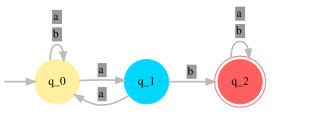

In [76]:
contains_ab.graph()

In [77]:
contains_ab.save_animated_svg("bbaabbbaaaaaaaabaaaaa", show=True)

In [78]:
contains_ab.accepts("bbaabbbaaaaaaaabaaaaa")

True

In [79]:
contains_ab.print_transitions("bbaabbbaaaaaaaabaaaaa")

{q_0},
 b → {q_0},
 b → {q_0},
 a → {q_0, q_1},
 a → {q_0, q_1},
 b → {q_0, q_2},
 b → {q_0, q_2},
 b → {q_0, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 b → {q_0, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 a → {q_0, q_1, q_2},
 

In [80]:
res=contains_ab.delta_extended(None,"bbaabbbaaaaaaaabaaaaa")
res

{'q_0', 'q_1', 'q_2'}

In [81]:
print(f"Con {res} Se acepta?", "Sí" if contains_ab.acceptor(res) else "No" )

Con {'q_2', 'q_0', 'q_1'} Se acepta? Sí


In [82]:
res=bes_pares.delta_extended(None,"bbaabbbaaaaaaaabaaaaab")
print(f"Con {res} Se acepta?", "Sí" if contains_ab.acceptor(res) else "No" )

Con {'q_2', 'q_0'} Se acepta? Sí


In [83]:
res=bes_pares.delta_extended(None,"bbbbbbbbbbbbbbbaaaaaaaa")
print(f"Con {res} Se acepta?", "Sí" if contains_ab.acceptor(res) else "No" )

Con {'q_0', 'q_1'} Se acepta? No


# Autómata finito no determinístico con transición epsilón

Ejemplifica la creación de un autómata finito no determinístico con transición epsilón

In [84]:
from maquinas.regular.ndfa_e import NonDeterministicFiniteAutomaton_epsilon as NDFA_e

In [85]:
# Cargando afnd-epsilon
aesb=load_fa("""
        |  a       |  b  | epsilon |
 ->q_0  | q_1      |     |  q_1    |
   q_1  | q_1      | q_2 |         |  
   q_2] |          |     |         |
"""
)

In [86]:
aesb.print_summary()

States  : q_0, q_1, q_2
Sigma   : a, b
Initial : q_0
Aceptors: {q_2}
Transitions:
 q_0,a → {q_1}
 q_0,ε → {q_1}
 q_1,a → {q_1}
 q_1,b → {q_2}

In [87]:
aesb

In [88]:
aesb.table()

,a,b,ε
⟶q_0,q_1,∅,q_1
q_1,q_1,q_2,∅
q_2,∅,∅,∅


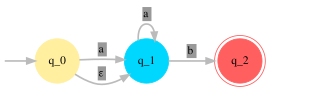

In [89]:
aesb.graph()

In [90]:
aesb.save_animated_svg("aaaaaaaaaaaaaaaaab", show=True)

In [91]:
aesb.accepts("aaaaaaaaaaaaaaaaab")

True

In [92]:
aesb.print_transitions("aaaaaaaaaaaaaaaaab")

{q_0, q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 a → {q_1},
 b → {q_2},
 

In [93]:
res=aesb.delta_extended(None,"aaaaaaaaaaaaaaaaab")
res

{'q_2'}

In [94]:
print(f"Con {res} Se acepta?", "Sí" if aesb.acceptor(res) else "No" )

Con {'q_2'} Se acepta? Sí


In [95]:
res=aesb.delta_extended(None,"aaaaaaaaaaaaaaaaabb")
print(f"Con {res} Se acepta?", "Sí" if aesb.acceptor(res) else "No" )

Con set() Se acepta? No


In [96]:
res=aesb.delta_extended(None,"bbbbbbbbbbbbbbbaaaaaaaa")
print(f"Con {res} Se acepta?", "Sí" if bes_pares.acceptor(res) else "No" )

Con set() Se acepta? No
